<a href="https://colab.research.google.com/github/basmmohamed/service_requests_MLproject/blob/main/Copy_of_NYC311_Eda_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC 311 — EDA and Preprocessing

**Project goal:** predict an NYC Department of Health and Mental Hygiene (DOHMH) complaint's closure-time category and investigate unresolved requests, repeated complaints, and changing complaint categories.

This notebook uses **one master dataset** and **one three-class target**. The code is kept deliberately simple so each step is easier to explain in the project Q&A.

### Target classes
- `within_7_days`: closed within 7 days.
- `8_to_30_days`: closed after 7 days but within 30 days.
- `not_within_30_days`: closed after 30 days, or still open after 30 days have been observed.


## Step 1 — Import libraries and set file names

These are the main tools used in the notebook. The observation cutoff is based on the export date in the supplied file name; update it if you use a newer export.

In [ ]:
# Import libraries
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# File names
RAW_FILE = "311_Service_Requests.csv"
MASTER_FILE = "nyc311_master.csv"
ARTIFACT_DIR = "nyc311_artifacts"

# Observation cutoff: latest date covered by the source export
OBSERVATION_CUTOFF = pd.Timestamp("2026-10-07")

# Reproducibility setting
SEED = 42

# Display all columns in DataFrames
pd.set_option("display.max_columns", 100)

## Step 2 — Load the CSV and inspect the columns

Load the NYC 311 CSV from Google Drive. Inspect its shape, column names, data types, and first few rows before making any cleaning decisions.

In [ ]:
# Load the CSV from the current folder or Google Drive

csv_path = RAW_FILE

# Check Google Drive if the file is not in the current folder
if not os.path.exists(csv_path):
    drive_path = os.path.join(
        "/content/drive/MyDrive/ML project ",
        RAW_FILE
    )

    if os.path.exists(drive_path):
        csv_path = drive_path

# If the file still cannot be found, offer an upload option
if not os.path.exists(csv_path):
    try:
        from google.colab import files

        print("Please upload the NYC 311 CSV file.")
        uploaded = files.upload()
        csv_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            f"Could not find {RAW_FILE}. "
            "Place the CSV beside the notebook or upload it."
        )

# Read the data
Service_Requests_311_df = pd.read_csv(csv_path, low_memory=False)

print("Loaded file:", csv_path)
print("Dataset shape:", Service_Requests_311_df.shape)
print("\nColumn names:")
print(Service_Requests_311_df.columns.tolist())

display(Service_Requests_311_df.head())
display(Service_Requests_311_df.dtypes.astype(str).to_frame("data_type"))

Loaded file: /content/drive/MyDrive/ML project /311_Service_Requests.csv
Dataset shape: (150687, 20)

Column names:
['Unique Key', 'Created Date', 'Closed Date', 'Agency Name', 'Problem (formerly Complaint Type)', 'Problem Detail (formerly Descriptor)', 'Location Type', 'Street Name', 'Address Type', 'City', 'Status', 'Due Date', 'Resolution Description', 'Resolution Action Updated Date', 'Borough', 'X Coordinate (State Plane)', 'Y Coordinate (State Plane)', 'Open Data Channel Type', 'Latitude', 'Longitude']


,Unique Key,Created Date,Closed Date,Agency Name,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Location Type,Street Name,Address Type,City,Status,Due Date,Resolution Description,Resolution Action Updated Date,Borough,X Coordinate (State Plane),Y Coordinate (State Plane),Open Data Channel Type,Latitude,Longitude
0,63578825,12/31/2024 11:48:31 PM,12/31/2024 11:48:31 PM,Department of Health and Mental Hygiene,Rodent,Condition Attracting Rodents,Commercial Building,EAST 96 STREET,ADDRESS,NEW YORK,Closed,NaN,The Department of Health and Mental Hygiene in...,01/10/2025 01:12:06 PM,MANHATTAN,"997,754","225,643",MOBILE,40.786004,-73.951236
1,63584738,12/31/2024 11:57:19 PM,03/02/2025 12:12:17 AM,Department of Health and Mental Hygiene,Food Establishment,Rodents/Insects/Garbage,Restaurant/Bar/Deli/Bakery,BROADWAY,ADDRESS,NEW YORK,Closed,NaN,The NYC Health Department has responded to you...,03/02/2025 12:12:20 AM,MANHATTAN,"1,000,024","244,098",ONLINE,40.836654,-73.942995
2,63575331,01/01/2025 12:08:11 AM,02/12/2025 10:19:14 PM,Department of Health and Mental Hygiene,Smoking or Vaping,Allowed in Smoke Free Area,Other,BROADWAY,ADDRESS,BRONX,Closed,NaN,The NYC Health Department has responded to you...,02/12/2025 10:19:18 PM,BRONX,"1,012,681","266,918",PHONE,40.899256,-73.897158
3,63578839,01/01/2025 12:15:17 AM,02/12/2025 10:19:15 PM,Department of Health and Mental Hygiene,Smoking or Vaping,Sign Inadequate,Residential Building,BROADWAY,ADDRESS,BRONX,Closed,NaN,The NYC Health Department has responded to you...,02/12/2025 10:19:20 PM,BRONX,"1,012,681","266,918",PHONE,40.899256,-73.897158
4,63580473,01/01/2025 12:43:43 AM,01/02/2025 10:24:48 AM,Department of Health and Mental Hygiene,Rodent,Rat Sighting,3+ Family Apt. Building,MORGAN AVENUE,ADDRESS,BROOKLYN,Closed,NaN,This service request was closed because the De...,01/01/2025 12:43:43 AM,BROOKLYN,"1,003,065","196,930",ONLINE,40.707184,-73.932137


,data_type
Unique Key,int64
Created Date,object
Closed Date,object
Agency Name,object
Problem (formerly Complaint Type),object
Problem Detail (formerly Descriptor),object
Location Type,object
Street Name,object
Address Type,object
City,object


## Step 3— Basic data-quality audit

This audit informs the EDA. We check missingness, exact duplicates, repeated complaint IDs, and columns with no variation. We do not automatically delete every row with missing values.

In [ ]:
# Step 3: Basic data-quality audit

# Keep DOHMH requests without filtering by year
agency_col = "Agency Name"

if agency_col in Service_Requests_311_df.columns:
    agency_text = Service_Requests_311_df[agency_col].astype("string").str.lower()

    data = Service_Requests_311_df[
        agency_text.str.contains(
            "department of health and mental hygiene",
            na=False
        )
    ].copy()
else:
    raise ValueError("Agency Name column was not found.")

print("Dataset shape:", data.shape)

# 1. Check missing values count and mean percentage
missing = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(1)
}).sort_values("missing_percent", ascending=False)

# Display only columns with missing values greater than zero
display(missing[missing["missing_count"] > 0])

# 2. Check exact duplicate rows
print("Exact duplicate rows:", data.duplicated().sum())

# 3. Check repeated complaint IDs
if "Unique Key" in data.columns:
    print(
        "Rows with repeated complaint IDs:",
        data["Unique Key"].duplicated(keep=False).sum()
    )

    print(
        "Distinct complaint IDs:",
        data["Unique Key"].nunique(dropna=True)
    )

# 4. Identify empty and constant columns
empty_columns = data.columns[
    data.isna().all()
].tolist()

constant_columns = [
    c for c in data.columns
    if data[c].nunique(dropna=False) <= 1
]

print("Entirely empty columns:", empty_columns)
print("Constant columns:", constant_columns)

Dataset shape: (150687, 20)


,missing_count,missing_percent
Due Date,150687,100.0
Closed Date,13652,9.1
Resolution Description,10640,7.1
Resolution Action Updated Date,9962,6.6
City,2660,1.8
Problem Detail (formerly Descriptor),1627,1.1
Y Coordinate (State Plane),437,0.3
X Coordinate (State Plane),458,0.3
Latitude,462,0.3
Longitude,462,0.3


Exact duplicate rows: 0
Rows with repeated complaint IDs: 0
Distinct complaint IDs: 150687
Entirely empty columns: ['Due Date']
Constant columns: ['Agency Name', 'Due Date']


## Step 4 — EDA: missing values and common complaint types

These plots help us identify which fields are incomplete and which complaint categories dominate. Missing closure dates are retained because they may represent requests still in progress.

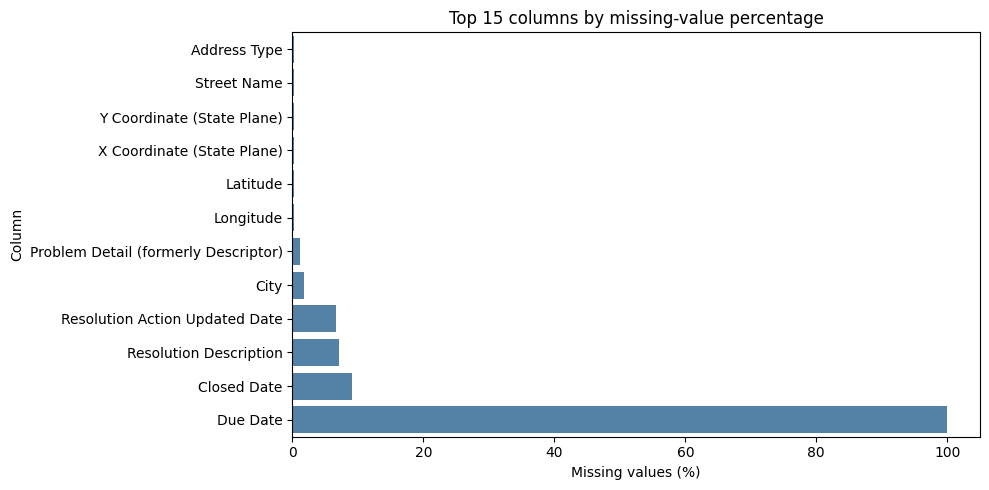

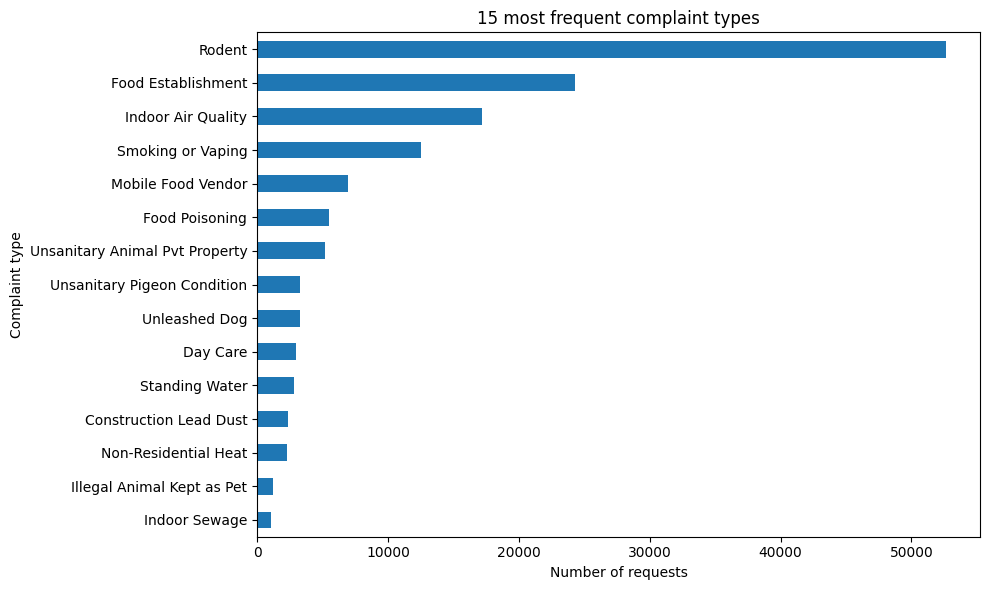

In [ ]:
plt.figure(figsize=(10, 5))
missing_to_plot = missing[missing["missing_count"] > 0].head(15).sort_values("missing_percent")
sns.barplot(x="missing_percent", y=missing_to_plot.index, data=missing_to_plot.reset_index().rename(columns={"index":"column"}), color="steelblue")
plt.title("Top 15 columns by missing-value percentage")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

complaint_col = "Problem (formerly Complaint Type)"
if complaint_col in data.columns:
    top_types = data[complaint_col].fillna("Missing").value_counts().head(15).sort_values()
    plt.figure(figsize=(10, 6))
    top_types.plot(kind="barh")
    plt.title("15 most frequent complaint types")
    plt.xlabel("Number of requests")
    plt.ylabel("Complaint type")
    plt.tight_layout()
    plt.show()

## Step 5— EDA: boroughs and monthly request volume

These plots describe where and when requests occur. Changing volume or category mix motivates a time-aware evaluation later.

/tmp/ipykernel_2459/38622106.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[created_col] = pd.to_datetime(


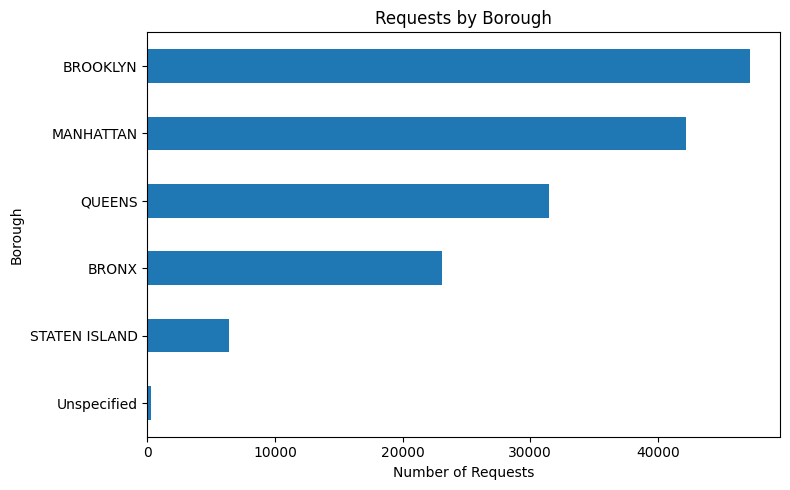

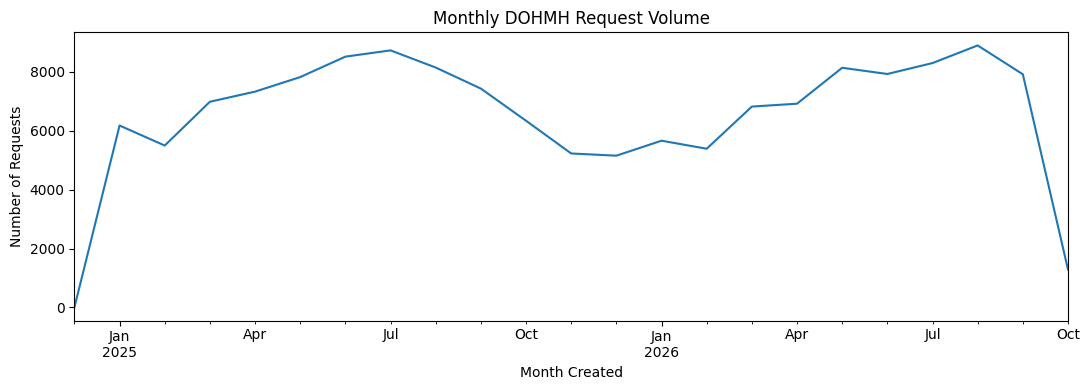

Rows with invalid or missing creation dates: 0


In [ ]:
# Step 5: Requests by borough and monthly request volume

# Make sure the creation date is in datetime format
created_col = "Created Date"

data[created_col] = pd.to_datetime(
    data[created_col],
    errors="coerce"
)

# 1. Number of requests by borough
if "Borough" in data.columns:
    borough_counts = (
        data["Borough"]
        .fillna("Missing")
        .value_counts()
        .sort_values()
    )

    plt.figure(figsize=(8, 5))
    borough_counts.plot(kind="barh")
    plt.title("Requests by Borough")
    plt.xlabel("Number of Requests")
    plt.ylabel("Borough")
    plt.tight_layout()
    plt.show()

# 2. Number of requests created each month
monthly_data = data.dropna(subset=[created_col])

monthly_volume = (
    monthly_data
    .set_index(created_col)
    .resample("MS")
    .size()
)

plt.figure(figsize=(11, 4))
monthly_volume.plot()

plt.title("Monthly DOHMH Request Volume")
plt.xlabel("Month Created")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

# Report records with invalid creation dates
print(
    "Rows with invalid or missing creation dates:",
    data[created_col].isna().sum()
)

## Step 6 — EDA: closure duration and unresolved requests

Closure duration is an outcome used for analysis and target construction. It is **not** an input feature for prediction, because the actual closure date is not known at submission time. Negative durations are flagged for investigation rather than silently treated as valid outcomes.

/tmp/ipykernel_2459/3527477105.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[closed_col] = pd.to_datetime(data[closed_col], errors="coerce")


Missing closure dates: 13652
Negative closure durations: 0
Zero-day closures: 29769
Closures longer than 30 days: 43987


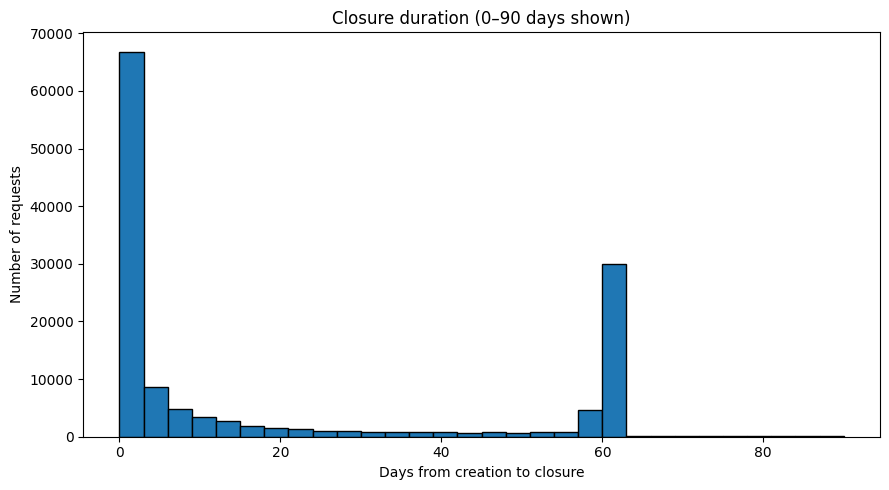

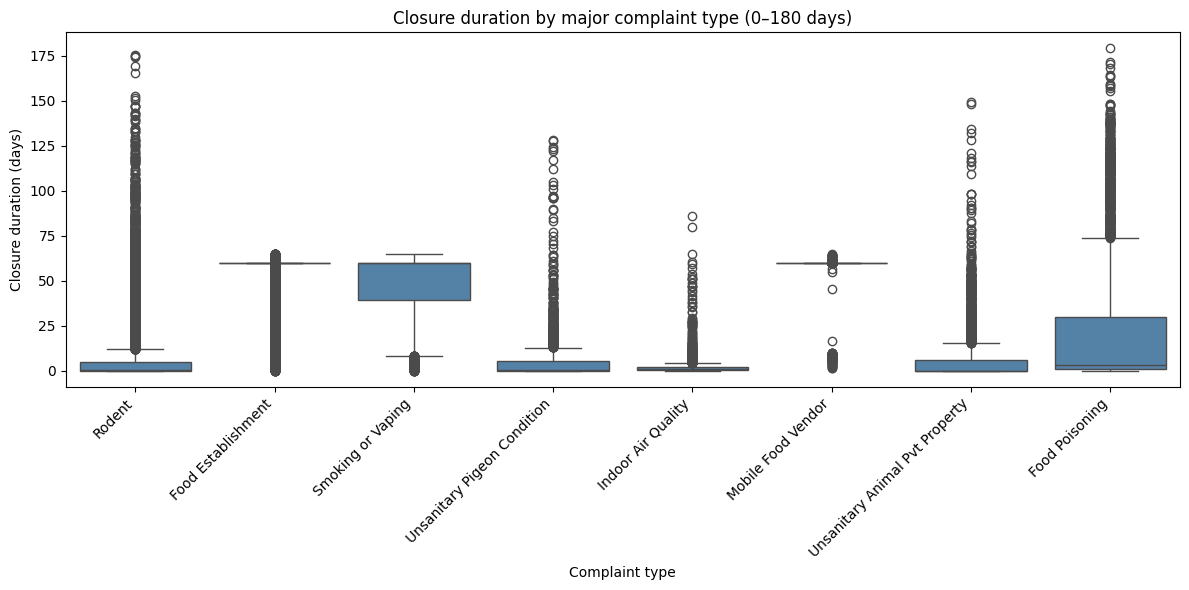

In [ ]:
closed_col = "Closed Date"
if closed_col in data.columns:
    data[closed_col] = pd.to_datetime(data[closed_col], errors="coerce")
    data["closure_duration_days_eda"] = (data[closed_col] - data[created_col]).dt.total_seconds() / 86400
    valid_duration = data["closure_duration_days_eda"].dropna()

    print("Missing closure dates:", data[closed_col].isna().sum())
    print("Negative closure durations:", (valid_duration < 0).sum())
    print("Zero-day closures:", (valid_duration == 0).sum())
    print("Closures longer than 30 days:", (valid_duration > 30).sum())

    plt.figure(figsize=(9, 5))
    plt.hist(valid_duration[(valid_duration >= 0) & (valid_duration <= 90)], bins=30, edgecolor="black")
    plt.title("Closure duration (0–90 days shown)")
    plt.xlabel("Days from creation to closure")
    plt.ylabel("Number of requests")
    plt.tight_layout()
    plt.show()

    if complaint_col in data.columns:
        main_types = data[complaint_col].value_counts().head(8).index
        duration_by_type = data.loc[data[complaint_col].isin(main_types) & data["closure_duration_days_eda"].between(0, 180)]
        plt.figure(figsize=(12, 6))
        sns.boxplot(data=duration_by_type, x=complaint_col, y="closure_duration_days_eda", color="steelblue")
        plt.title("Closure duration by major complaint type (0–180 days)")
        plt.xlabel("Complaint type")
        plt.ylabel("Closure duration (days)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## Step 7— EDA: repeated complaints and category changes

Repeated IDs may be duplicate records, while repeated complaints on the same street can be genuine separate requests. The street-based count is only an approximate recurrence measure, not proof that two reports are the same issue.

Rows with repeated IDs: 0


,Unique Key,Created Date,Closed Date,Agency Name,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Location Type,Street Name,Address Type,City,Status,Due Date,Resolution Description,Resolution Action Updated Date,Borough,X Coordinate (State Plane),Y Coordinate (State Plane),Open Data Channel Type,Latitude,Longitude,closure_duration_days_eda


Most frequent street/borough combinations:


request_count
Borough   Street Name                     
MANHATTAN 2 AVENUE                    2105
          5 AVENUE                    1855
          BROADWAY                    1646
          AMSTERDAM AVENUE             957
QUEENS    JAMAICA AVENUE               948
BRONX     WOODYCREST AVENUE            798
MANHATTAN YORK AVENUE                  688
BRONX     GRAND CONCOURSE              677
MANHATTAN 1 AVENUE                     648
QUEENS    34 STREET                    643

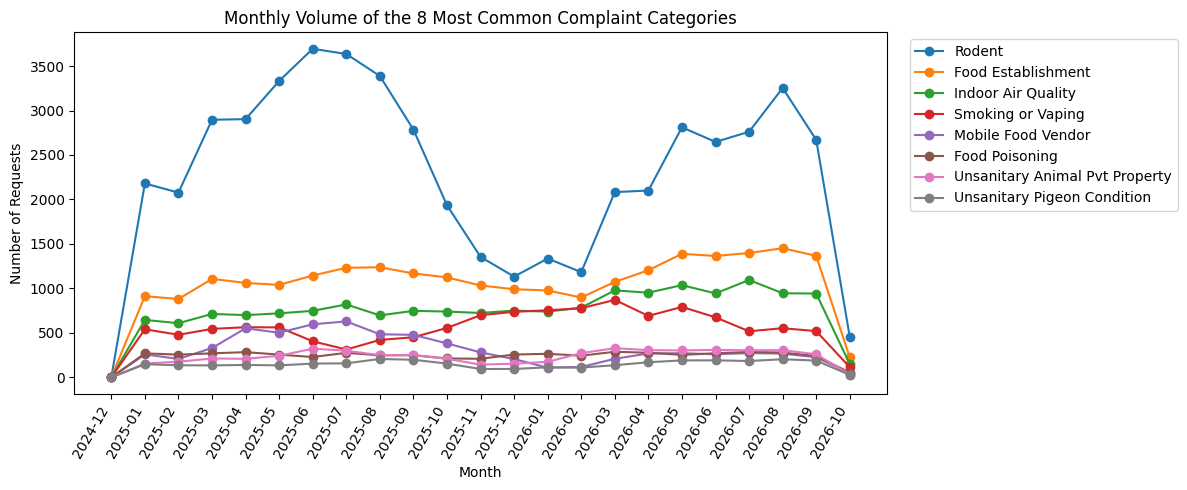

In [ ]:
# Step 7: Repeated complaints and changing categories

# 1. Check whether complaint IDs are repeated
if "Unique Key" in data.columns:
    repeated_ids = data[
        data["Unique Key"].duplicated(keep=False)
    ].sort_values("Unique Key")

    print("Rows with repeated IDs:", len(repeated_ids))
    display(repeated_ids.head(10))


# 2. Find streets with the most requests
if "Street Name" in data.columns and "Borough" in data.columns:
    recurring = data.copy()

    recurring["Street Name"] = (
        recurring["Street Name"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    street_counts = (
        recurring.dropna(subset=["Street Name"])
        .groupby(["Borough", "Street Name"])
        .size()
        .sort_values(ascending=False)
    )

    print("Most frequent street/borough combinations:")
    display(street_counts.head(10).to_frame("request_count"))


# 3. Show how common complaint categories change over time
if complaint_col in data.columns:
    month_column = data[created_col].dt.to_period("M").astype(str)

    type_month = pd.crosstab(month_column, data[complaint_col])

    top_categories = data[complaint_col].value_counts().head(8).index
    type_month = type_month.reindex(
        columns=top_categories,
        fill_value=0
    )

    plt.figure(figsize=(12, 5))

    for category in type_month.columns:
        plt.plot(
            type_month.index,
            type_month[category],
            marker="o",
            label=str(category)
        )

    plt.title("Monthly Volume of the 8 Most Common Complaint Categories")
    plt.xlabel("Month")
    plt.ylabel("Number of Requests")
    plt.xticks(rotation=60, ha="right")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Step 8 — EDA: Correlation and categorical associations

We use Pearson correlation to explore numerical relationships and Cramér's V to measure associations between categorical variables. These plots help identify potentially redundant features, but association does not imply causation.

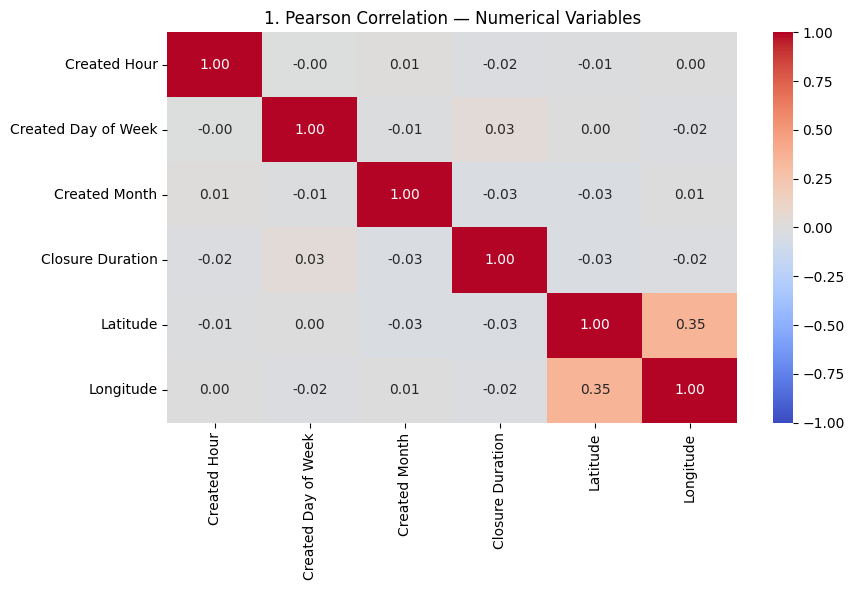

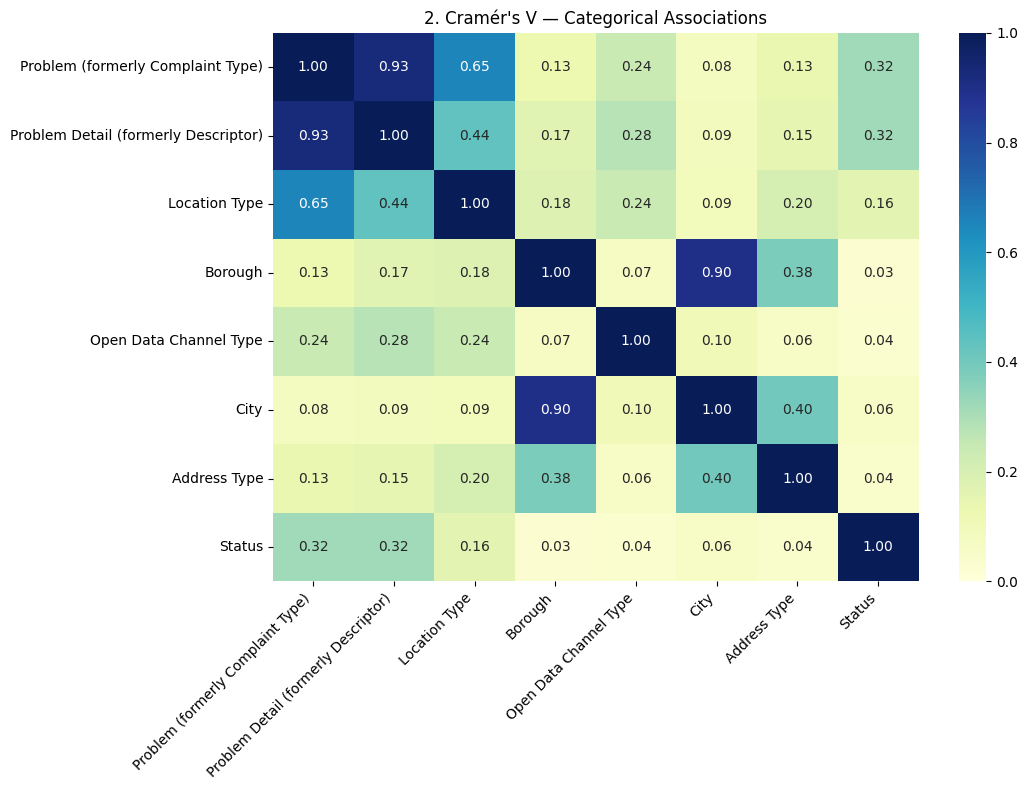

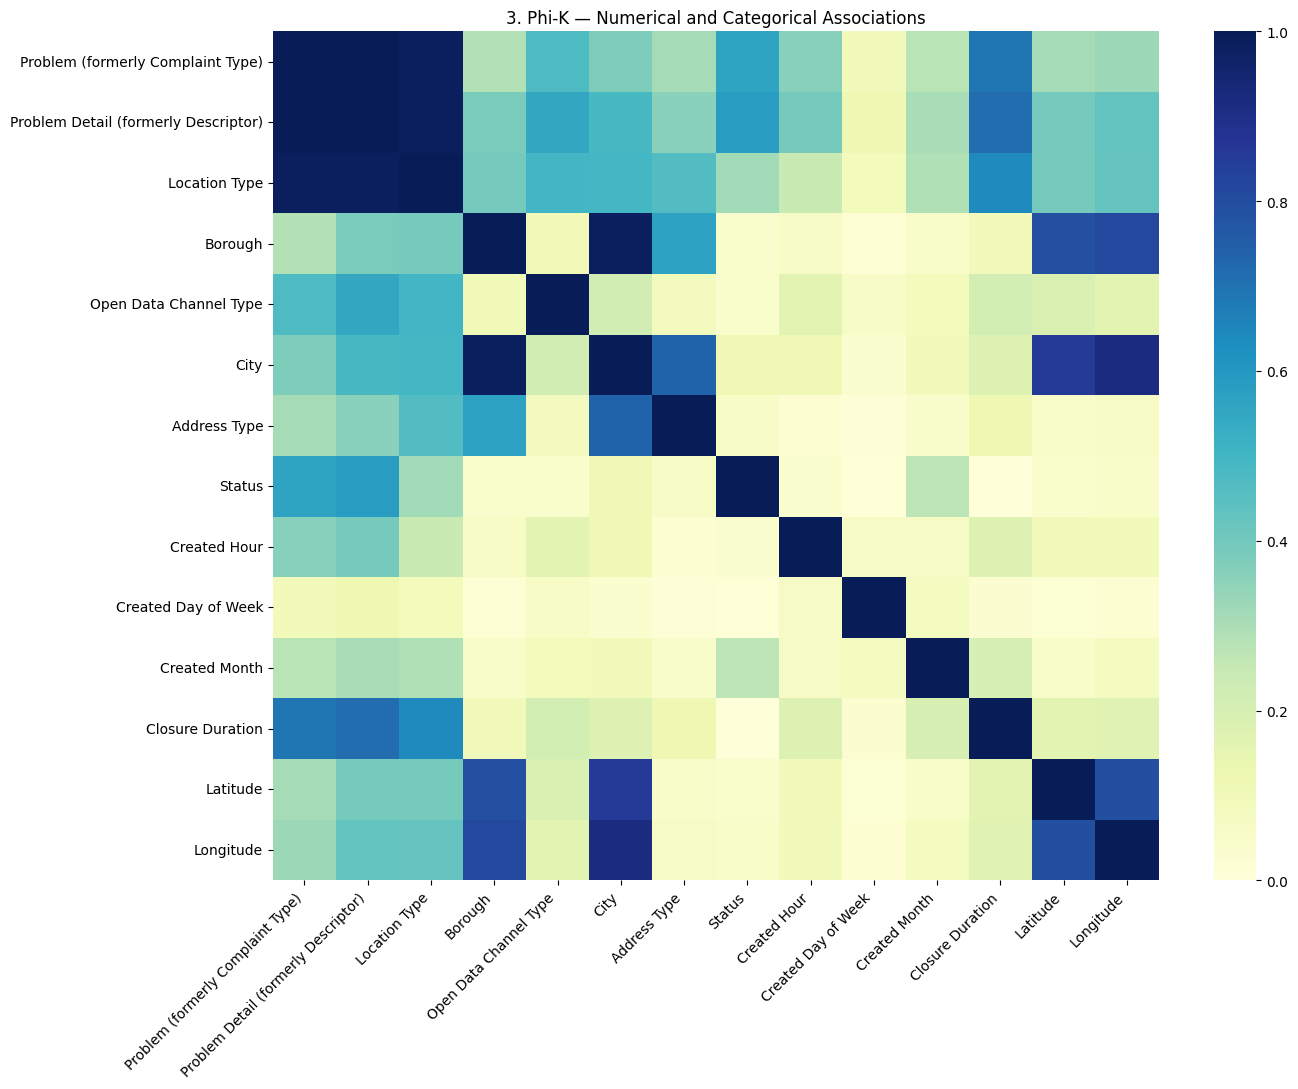

All three association heatmaps were created.


In [ ]:
# Step 9: Explore numerical, categorical, and mixed-type associations

# Install Phi-K for the mixed-type association heatmap
%pip -q install phik

import phik
from scipy.stats import chi2_contingency


# --------------------------------------------------
# 1. PEARSON: Numerical variables
# --------------------------------------------------

numeric_data = pd.DataFrame(index=data.index)

# Features derived from the complaint creation date
dates = pd.to_datetime(data[created_col], errors="coerce")

numeric_data["Created Hour"] = dates.dt.hour
numeric_data["Created Day of Week"] = dates.dt.dayofweek
numeric_data["Created Month"] = dates.dt.month

# Closure duration is for EDA only, not a model input
if "closure_duration_days_eda" in data.columns:
    duration = pd.to_numeric(
        data["closure_duration_days_eda"], errors="coerce"
    )

    # Exclude invalid negative durations from this analysis
    numeric_data["Closure Duration"] = duration.where(duration >= 0)

# Keep latitude and longitude as the selected coordinate pair
for col in ["Latitude", "Longitude"]:
    if col in data.columns:
        numeric_data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

pearson_corr = numeric_data.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("1. Pearson Correlation — Numerical Variables")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. CRAMER'S V: Categorical variables
# --------------------------------------------------

categorical_cols = [
    "Problem (formerly Complaint Type)",
    "Problem Detail (formerly Descriptor)",
    "Location Type",
    "Borough",
    "Open Data Channel Type",
    "City",
    "Address Type",
    "Status"
]

# Keep only columns that exist in the dataset
categorical_cols = [
    col for col in categorical_cols if col in data.columns
]


def cramers_v(x, y):
    """Calculate the association between two categorical variables."""
    table = pd.crosstab(
        x.fillna("Missing").astype(str),
        y.fillna("Missing").astype(str)
    )

    # Association cannot be calculated if a variable has only one category
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    denominator = n * min(
        table.shape[0] - 1,
        table.shape[1] - 1
    )

    if denominator == 0:
        return np.nan

    return np.sqrt(chi2 / denominator)


# Calculate Cramér's V for every pair of categorical variables
cramers_matrix = pd.DataFrame(
    np.nan,
    index=categorical_cols,
    columns=categorical_cols
)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0
        else:
            cramers_matrix.loc[col1, col2] = cramers_v(
                data[col1], data[col2]
            )

plt.figure(figsize=(11, 8))
sns.heatmap(
    cramers_matrix,
    annot=True,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    fmt=".2f"
)
plt.title("2. Cramér's V — Categorical Associations")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. PHI-K: Numerical and categorical variables together
# --------------------------------------------------

mixed_data = pd.DataFrame(index=data.index)

# Add the selected categorical variables
for col in categorical_cols:
    mixed_data[col] = data[col].fillna("Missing").astype(str)

# Add the numerical variables
for col in numeric_data.columns:
    mixed_data[col] = numeric_data[col]

numeric_cols = numeric_data.columns.tolist()

# Calculate mixed-type associations
phik_matrix = mixed_data.phik_matrix(
    interval_cols=numeric_cols
)

plt.figure(figsize=(14, 11))
sns.heatmap(
    phik_matrix,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)
plt.title("3. Phi-K — Numerical and Categorical Associations")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


print("All three association heatmaps were created.")

### Interpretation of the Correlation and Association Results

**1. Pearson Correlation — Numerical Variables**

Most numerical variable pairs have correlations close to zero (between approximately −0.03 and 0.03), indicating very weak linear relationships. Latitude and longitude have a positive correlation of **0.35**, indicating a moderate positive linear relationship in this dataset.

**Preprocessing decision:** Keep the creation-time features for further analysis. Initially retain latitude and longitude as one coordinate pair, and evaluate whether they improve prediction. Pearson correlation alone does not determine whether a feature is useful.

**2. Cramér's V — Categorical Variables**

The strongest associations are between complaint type and complaint descriptor (**0.93**) and between borough and city (**0.90**). Complaint type and location type also show a relatively strong association (**0.65**). Other notable associations include complaint type and status (**0.32**) and complaint descriptor and status (**0.32**).

**Preprocessing decision:** Keep complaint type and descriptor initially, but recognize that they contain overlapping information. Because borough and city are strongly associated, retain borough as the simpler initial geographic feature and exclude city from the initial model inputs. Address Type can also be excluded initially because the category `ADDRESS` dominates the dataset.

**3. Phi-K — Numerical and Categorical Associations**

The mixed-type heatmap shows strong associations among complaint type, complaint descriptor, and location type. It also shows strong geographic associations among borough, city, latitude, and longitude. Closure duration appears more strongly associated with complaint characteristics than with the creation-time features.

**Preprocessing decision:** Avoid using multiple overlapping geographic representations without a clear reason. Start with borough and compare model performance after adding latitude and longitude. Keep closure duration for historical analysis and target construction only; it must not be used as a model input.

**Important limitations:** These measurements describe associations, not causal relationships or guaranteed predictive value. Status and closure duration are included for historical EDA only because they may reveal information unavailable when a complaint is submitted. The association heatmaps guide feature-selection decisions, which should ultimately be evaluated using training and validation data.

## Step 9 — EDA Findings and Preprocessing Decisions

The EDA guides the following preparation decisions:

1. Preserve unresolved requests and leave outcomes unknown when the observation period is insufficient.
2. Remove exact duplicate rows, but investigate repeated complaint IDs before removing records.
3. Remove entirely empty and constant columns because they provide no useful variation.
4. Keep complaint type and descriptor initially, but recognize their strong association.
5. Use borough as the initial geographic feature; exclude city and address type from the initial model inputs, and evaluate whether adding latitude and longitude improves prediction.
6. Keep creation-time features because they are available at submission.
7. Retain closure dates, closure duration, status, and resolution information for historical analysis, but exclude them from model inputs to prevent leakage.
8. Use a chronological evaluation split and fit data-dependent preprocessing only on training data.

## Step 10 — Preprocessing: Standardize columns and remove duplicates

Standardize column names, remove exact duplicate rows, and identify repeated complaint IDs without automatically deleting them. Remove entirely empty and constant columns, and save a column map documenting the cleaning decisions.

In [ ]:
# Step 10: Standardize columns and remove duplicates

# 1. Start with the data after EDA
# Remove temporary columns used only for plotting
master = data.drop(
    columns=["closure_duration_days_eda"],
    errors="ignore"
).copy()

# 2. Standardize column names
original_columns = master.columns.tolist()

master.columns = (
    master.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# 3. Remove exact duplicate rows
before = len(master)
master = master.drop_duplicates().copy()

print("Exact duplicate rows removed:", before - len(master))

# 4. Investigate repeated complaint IDs
if "unique_key" in master.columns:
    print(
        "Rows with repeated complaint IDs:",
        master["unique_key"].duplicated(keep=False).sum()
    )

# 5. Identify entirely empty columns
empty_columns = [
    c for c in master.columns
    if master[c].isna().all()
]

# 6. Identify constant columns
constant_columns = [
    c for c in master.columns
    if master[c].nunique(dropna=False) <= 1
    and c not in empty_columns
]

print("Entirely empty columns:", empty_columns)
print("Constant columns:", constant_columns)

# 7. Save a map of original and standardized column names
column_map = pd.DataFrame({
    "original_column": original_columns,
    "standardized_column": master.columns
})

column_map["action"] = column_map["standardized_column"].apply(
    lambda c: "dropped: empty" if c in empty_columns
    else "dropped: constant" if c in constant_columns
    else "kept"
)

column_map.to_csv("nyc311_column_map.csv", index=False)

# 8. Remove columns with no useful variation
master = master.drop(
    columns=empty_columns + constant_columns
).copy()

print("Master dataset shape after cleaning:", master.shape)

Exact duplicate rows removed: 0
Rows with repeated complaint IDs: 0
Entirely empty columns: ['due_date']
Constant columns: ['agency_name']
Master dataset shape after cleaning: (150687, 18)


## Step 11 — Create one target: `closure_time_category`

Create three closure-time classes using the creation and closure dates. Requests still open after 30 fully observed days are class `not_within_30_days`. Requests without enough observation time, invalid dates, and negative closure durations keep an unknown target.

In [ ]:
# Step 11: Create closure duration and the target

created = "created_date"
closed = "closed_date"

# Convert the date columns to datetime
master[created] = pd.to_datetime(master[created], errors="coerce")
master[closed] = pd.to_datetime(master[closed], errors="coerce")

# Calculate closure duration in days
master["closure_duration_days"] = (
    master[closed] - master[created]
).dt.total_seconds() / 86400

# Start with unknown outcomes
master["closure_time_category"] = pd.NA

duration = master["closure_duration_days"]

# Identify valid creation and closure dates
valid_created = master[created].notna()
valid_closed = (
    master[closed].notna()
    & valid_created
    & duration.ge(0)
)

# Class 1: Closed within 7 days
master.loc[
    valid_closed & duration.le(7),
    "closure_time_category"
] = "within_7_days"

# Class 2: Closed after 7 days but within 30 days
master.loc[
    valid_closed & duration.gt(7) & duration.le(30),
    "closure_time_category"
] = "8_to_30_days"

# Class 3: Closed after 30 days
master.loc[
    valid_closed & duration.gt(30),
    "closure_time_category"
] = "not_within_30_days"

# Class 3: Still open after a complete 30-day observation window
still_open = master[closed].isna() & valid_created

days_observed = (
    OBSERVATION_CUTOFF - master[created]
).dt.total_seconds() / 86400

master.loc[
    still_open & days_observed.ge(30),
    "closure_time_category"
] = "not_within_30_days"

# Summarize the target, including unknown outcomes
print("Target counts (including unknown):")

display(
    master["closure_time_category"]
    .value_counts(dropna=False)
    .rename_axis("closure_time_category")
    .to_frame("count")
)

print("\nNegative closure durations:",
      duration.lt(0).sum())

print("Unknown target labels:",
      master["closure_time_category"].isna().sum())

Target counts (including unknown):


,count
closure_time_category,
within_7_days,77194
not_within_30_days,53258
8_to_30_days,15854
<NA>,4381



Negative closure durations: 0
Unknown target labels: 4381


## Step 12 — Create prediction-time features

Create time features from the complaint creation date. Also count earlier requests on the same street and in the same borough. These features must use only information available when the complaint is submitted.

In [ ]:
# Step 12: Create prediction-time features

created = "created_date"
street_col = "street_name"
borough_col = "borough"

# 1. Create features from the creation date
master["created_hour"] = master[created].dt.hour
master["created_day_of_week"] = master[created].dt.dayofweek
master["created_month"] = master[created].dt.month

master["created_is_weekend"] = (
    master["created_day_of_week"].isin([5, 6]).astype(int)
)

# 2. Prepare the historical recurrence feature
# Missing street or borough means the historical count is unknown
master["prior_requests_same_street_borough"] = np.nan

valid_rows = master[
    master[created].notna()
    & master[street_col].notna()
    & master[borough_col].notna()
].copy()

# Standardize street names for matching
valid_rows[street_col] = (
    valid_rows[street_col]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Exclude blank street names
valid_rows = valid_rows[
    valid_rows[street_col].ne("")
].copy()

# Count requests at each exact timestamp
time_counts = (
    valid_rows
    .groupby(
        [borough_col, street_col, created],
        dropna=False
    )
    .size()
    .reset_index(name="requests_at_same_time")
)

# Sort each street's timestamps chronologically
time_counts = time_counts.sort_values(
    [borough_col, street_col, created]
)

# Count requests at strictly earlier timestamps
time_counts["prior_count"] = (
    time_counts
    .groupby([borough_col, street_col])["requests_at_same_time"]
    .cumsum()
    - time_counts["requests_at_same_time"]
)

# Attach the historical count to each original complaint
valid_rows["_row_index"] = valid_rows.index

valid_rows = valid_rows.merge(
    time_counts[
        [borough_col, street_col, created, "prior_count"]
    ],
    on=[borough_col, street_col, created],
    how="left"
)

master.loc[
    valid_rows["_row_index"],
    "prior_requests_same_street_borough"
] = valid_rows["prior_count"].to_numpy()

# 3. Check the results
time_features = [
    "created_hour",
    "created_day_of_week",
    "created_month",
    "created_is_weekend",
    "prior_requests_same_street_borough"
]

print("Created prediction-time features:")
display(master[time_features].head())

print(
    "Rows without a usable historical recurrence count:",
    master["prior_requests_same_street_borough"].isna().sum()
)

Created prediction-time features:


,created_hour,created_day_of_week,created_month,created_is_weekend,prior_requests_same_street_borough
0,23,1,12,0,0.0
1,23,1,12,0,0.0
2,0,2,1,0,0.0
3,0,2,1,0,1.0
4,0,2,1,0,0.0


Rows without a usable historical recurrence count: 349


## Step 13 — Final checks and save the master dataset

Check the target distribution, confirm that unknown outcomes remain in the dataset, and save one master CSV containing the historical fields and derived features needed for later modeling.

Master dataset shape: (150687, 25)

Target counts (including unknown):


,count
closure_time_category,
within_7_days,77194
not_within_30_days,53258
8_to_30_days,15854
<NA>,4381



Class distribution among known outcomes:


,count,percent
closure_time_category,,
within_7_days,77194,52.8
8_to_30_days,15854,10.8
not_within_30_days,53258,36.4


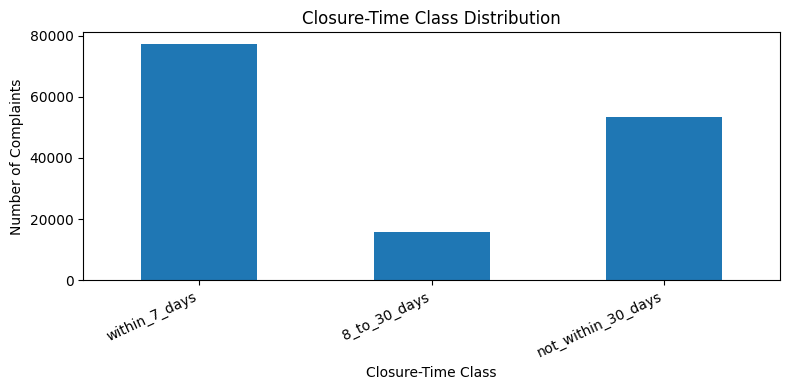


Saved master dataset: nyc311_master.csv
Total rows: 150687
Known target rows: 146306
Unknown target rows: 4381


In [ ]:
# Step 13: Final checks and save the master dataset

# 1. Check the dataset shape
print("Master dataset shape:", master.shape)

# 2. Check target counts, including unknown outcomes
target_counts = master["closure_time_category"].value_counts(
    dropna=False
)

print("\nTarget counts (including unknown):")
display(target_counts.to_frame("count"))

# 3. Show class distribution among known outcomes
class_order = [
    "within_7_days",
    "8_to_30_days",
    "not_within_30_days"
]

known_targets = master["closure_time_category"].dropna()

class_summary = (
    known_targets.value_counts()
    .reindex(class_order, fill_value=0)
    .to_frame("count")
)

class_summary["percent"] = (
    class_summary["count"] / len(known_targets) * 100
).round(1)

print("\nClass distribution among known outcomes:")
display(class_summary)

# 4. Plot the known target classes
plt.figure(figsize=(8, 4))

class_summary["count"].plot(kind="bar")

plt.title("Closure-Time Class Distribution")
plt.xlabel("Closure-Time Class")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# 5. Save one master dataset
master.to_csv(MASTER_FILE, index=False)

print("\nSaved master dataset:", MASTER_FILE)
print("Total rows:", len(master))
print("Known target rows:", master["closure_time_category"].notna().sum())
print("Unknown target rows:", master["closure_time_category"].isna().sum())

## Step 14 — Select model features and target

Select features that would be available when a complaint is submitted. Keep identifiers and post-submission information in the master dataset for analysis, but exclude them from model inputs. Rows with unknown target labels remain in the master dataset and are excluded from supervised modeling.

In [ ]:
# Step 14: Select X (inputs) and y (target)

TARGET = "closure_time_category"

# Categorical features available at submission
categorical_features = [
    "problem_formerly_complaint_type",
    "location_type",
    "borough",
    "open_data_channel_type"
]

# Numerical features available at submission
numeric_features = [
    "latitude",
    "longitude",
    "created_hour",
    "created_day_of_week",
    "created_month",
    "created_is_weekend",
    "prior_requests_same_street_borough"
]

# Combine the selected input features
feature_columns = categorical_features + numeric_features

# Check that all selected features exist
missing_columns = [
    col for col in feature_columns + [TARGET, "created_date"]
    if col not in master.columns
]

if missing_columns:
    raise ValueError(f"Missing columns in master dataset: {missing_columns}")

# Keep rows with known target labels for supervised modeling
model_data = master[master[TARGET].notna()].copy()

# Sort complaints chronologically
model_data = model_data.sort_values(
    "created_date"
).reset_index(drop=True)

# Separate model inputs and target
X = model_data[feature_columns].copy()
y = model_data[TARGET].copy()

# Check the results
print("Modeling dataset shape:", model_data.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(feature_columns)

print("\nTarget distribution:")
display(y.value_counts().to_frame("count"))

print("\nMissing values in selected features:")
display(X.isna().sum().to_frame("missing_count"))

print("\nCreation-date range:")
print(
    model_data["created_date"].min(),
    "to",
    model_data["created_date"].max()
)

Modeling dataset shape: (146306, 25)
X shape: (146306, 11)
y shape: (146306,)

Input features:
['problem_formerly_complaint_type', 'location_type', 'borough', 'open_data_channel_type', 'latitude', 'longitude', 'created_hour', 'created_day_of_week', 'created_month', 'created_is_weekend', 'prior_requests_same_street_borough']

Target distribution:


,count
closure_time_category,
within_7_days,77194
not_within_30_days,53258
8_to_30_days,15854



Missing values in selected features:


,missing_count
problem_formerly_complaint_type,0
location_type,0
borough,0
open_data_channel_type,0
latitude,445
longitude,445
created_hour,0
created_day_of_week,0
created_month,0
created_is_weekend,0



Creation-date range:
2024-12-31 23:48:31 to 2026-10-04 18:15:46


## Step 15 — Create a chronological train/test split

Sort complaints by creation date and use earlier complaints for training and later complaints for testing. Keep the test set untouched during model tuning. Preprocessing will be fitted later within each training fold.

In [ ]:
# Step 15: Split data chronologically

# Find the approximate 80% split point
split_point = int(len(model_data) * 0.8)

# Keep complaints with identical timestamps in the same split
split_date = model_data["created_date"].iloc[split_point]

train_mask = model_data["created_date"] < split_date
test_mask = model_data["created_date"] >= split_date

# Split the input features and target
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Check the split
print("Split date:", split_date)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining date range:")
print(
    model_data.loc[train_mask, "created_date"].min(),
    "to",
    model_data.loc[train_mask, "created_date"].max()
)

print("\nTesting date range:")
print(
    model_data.loc[test_mask, "created_date"].min(),
    "to",
    model_data.loc[test_mask, "created_date"].max()
)

print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("count"))

print("\nTesting class distribution:")
display(y_test.value_counts().to_frame("count"))

# Save the split files
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_frame("closure_time_category").to_csv(
    "y_train.csv", index=False
)
y_test.to_frame("closure_time_category").to_csv(
    "y_test.csv", index=False
)

print("\nSaved X_train.csv, X_test.csv, y_train.csv, and y_test.csv")

Split date: 2026-06-03 13:55:52

Training rows: 117044
Testing rows: 29262

Training date range:
2024-12-31 23:48:31 to 2026-06-03 13:54:20

Testing date range:
2026-06-03 13:55:52 to 2026-10-04 18:15:46

Training class distribution:


,count
closure_time_category,
within_7_days,66401
not_within_30_days,42326
8_to_30_days,8317



Testing class distribution:


,count
closure_time_category,
not_within_30_days,10932
within_7_days,10793
8_to_30_days,7537



Saved X_train.csv, X_test.csv, y_train.csv, and y_test.csv


## Step 16 — Save preprocessing and reproducibility artifacts

Save the unfitted preprocessing pipeline, feature definitions, target classes, split manifest, and package versions. These files allow the modeling workflow to reproduce preprocessing without fitting transformations on validation or test data.

In [ ]:
# Step 16: Save preprocessing and reproducibility artifacts

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn
import sys

# 1. Create the categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 2. Create the numerical preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Combine the preprocessing steps
preprocessor_template = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

# IMPORTANT: Do not fit this template in this notebook.

# 4. Create the artifact folder
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Save the unfitted preprocessing template
joblib.dump(
    preprocessor_template,
    os.path.join(ARTIFACT_DIR, "nyc311_preprocessor_template.joblib")
)

# 5. Save the feature names and target classes
class_names = [
    "within_7_days",
    "8_to_30_days",
    "not_within_30_days"
]

with open(
    os.path.join(ARTIFACT_DIR, "feature_columns.json"), "w"
) as f:
    json.dump(feature_columns, f, indent=2)

with open(
    os.path.join(ARTIFACT_DIR, "class_mapping.json"), "w"
) as f:
    json.dump(
        {"classes": class_names},
        f,
        indent=2
    )

# 6. Save the split manifest
train_manifest = model_data.loc[train_mask, [
    "unique_key", "created_date", TARGET
]].copy()
train_manifest["split"] = "train"

test_manifest = model_data.loc[test_mask, [
    "unique_key", "created_date", TARGET
]].copy()
test_manifest["split"] = "test"

split_manifest = pd.concat(
    [train_manifest, test_manifest],
    ignore_index=True
)

split_manifest.to_csv(
    os.path.join(ARTIFACT_DIR, "train_test_split_manifest.csv"),
    index=False
)

# 7. Save the current master dataset, including new features
master.to_csv(MASTER_FILE, index=False)

# 8. Save software versions
package_versions = {
    "python": sys.version,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__
}

with open(
    os.path.join(ARTIFACT_DIR, "package_versions.json"), "w"
) as f:
    json.dump(package_versions, f, indent=2)

print("Saved unfitted preprocessing template.")
print("Saved feature and class definitions.")
print("Saved chronological split manifest.")
print("Updated master dataset:", MASTER_FILE)
print("Artifacts folder:", ARTIFACT_DIR)

Saved unfitted preprocessing template.
Saved feature and class definitions.
Saved chronological split manifest.
Updated master dataset: nyc311_master.csv
Artifacts folder: nyc311_artifacts


## Step 17 — Verify the saved preprocessing template

Reload the saved preprocessing template and check that the training and testing files contain the expected features. The template remains unfitted so it can be fitted separately within each chronological cross-validation fold.

In [ ]:
# Step 17: Prepare model-ready data and export ZIP files

import os
import json
import zipfile
import sys
import sklearn
import joblib
import numpy as np
import pandas as pd

from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------
# 1. Build the preprocessing pipeline
# --------------------------------------------------

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

# --------------------------------------------------
# 2. Fit on training data only
# --------------------------------------------------

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Convert to dense numeric arrays for ANN and Random Forest
if sparse.issparse(X_train_transformed):
    X_train_transformed = X_train_transformed.toarray()

if sparse.issparse(X_test_transformed):
    X_test_transformed = X_test_transformed.toarray()

X_train_ready = np.asarray(
    X_train_transformed, dtype=np.float32
)

X_test_ready = np.asarray(
    X_test_transformed, dtype=np.float32
)

print("Training matrix shape:", X_train_ready.shape)
print("Testing matrix shape:", X_test_ready.shape)

# Save the transformed numeric feature matrices
np.save("X_train_ready.npy", X_train_ready)
np.save("X_test_ready.npy", X_test_ready)

# Save transformed feature names
transformed_feature_names = (
    preprocessor.get_feature_names_out().tolist()
)

# --------------------------------------------------
# 3. Encode the target for ANN
# --------------------------------------------------

class_names = [
    "within_7_days",
    "8_to_30_days",
    "not_within_30_days"
]

class_to_id = {
    name: i for i, name in enumerate(class_names)
}

y_train_ids = np.array(
    [class_to_id[label] for label in y_train],
    dtype=np.int64
)

y_test_ids = np.array(
    [class_to_id[label] for label in y_test],
    dtype=np.int64
)

# One-hot targets for ANN with softmax output
y_train_onehot = np.eye(
    len(class_names), dtype=np.float32
)[y_train_ids]

y_test_onehot = np.eye(
    len(class_names), dtype=np.float32
)[y_test_ids]

np.save("y_train_encoded.npy", y_train_ids)
np.save("y_test_encoded.npy", y_test_ids)
np.save("y_train_onehot.npy", y_train_onehot)
np.save("y_test_onehot.npy", y_test_onehot)

print("ANN target shape:", y_train_onehot.shape)
print("Target classes:", class_to_id)

# --------------------------------------------------
# 4. Save fitted and unfitted preprocessing pipelines
# --------------------------------------------------

os.makedirs(ARTIFACT_DIR, exist_ok=True)

# This fitted pipeline is for the final holdout workflow.
joblib.dump(
    preprocessor,
    os.path.join(ARTIFACT_DIR, "nyc311_preprocessor_fitted.joblib")
)

# Keep the unfitted template for cross-validation.
preprocessor_template = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

joblib.dump(
    preprocessor_template,
    os.path.join(ARTIFACT_DIR, "nyc311_preprocessor_template.joblib")
)

with open(
    os.path.join(ARTIFACT_DIR, "feature_columns.json"), "w"
) as f:
    json.dump(feature_columns, f, indent=2)

with open(
    os.path.join(ARTIFACT_DIR, "transformed_feature_names.json"), "w"
) as f:
    json.dump(transformed_feature_names, f, indent=2)

with open(
    os.path.join(ARTIFACT_DIR, "class_mapping.json"), "w"
) as f:
    json.dump(
        {
            "class_to_id": class_to_id,
            "classes": class_names
        },
        f,
        indent=2
    )

package_versions = {
    "python": sys.version,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__
}

with open(
    os.path.join(ARTIFACT_DIR, "package_versions.json"), "w"
) as f:
    json.dump(package_versions, f, indent=2)

# Save the current master dataset
master.to_csv(MASTER_FILE, index=False)

# --------------------------------------------------
# 5. Create the DATA ZIP
# --------------------------------------------------

data_files = [
    MASTER_FILE,
    "X_train.csv",
    "X_test.csv",
    "y_train.csv",
    "y_test.csv",
    "X_train_ready.npy",
    "X_test_ready.npy",
    "y_train_encoded.npy",
    "y_test_encoded.npy",
    "y_train_onehot.npy",
    "y_test_onehot.npy"
]

manifest_path = os.path.join(
    ARTIFACT_DIR, "train_test_split_manifest.csv"
)

# Include the split manifest in the data ZIP
data_files.append(manifest_path)

missing_files = [
    file for file in data_files
    if not os.path.exists(file)
]

if missing_files:
    raise FileNotFoundError(
        f"These expected files are missing: {missing_files}"
    )

with zipfile.ZipFile(
    "nyc311_data.zip", "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for file in data_files:
        zip_file.write(file, arcname=os.path.basename(file))

# --------------------------------------------------
# 6. Create the ARTIFACTS ZIP
# --------------------------------------------------

artifact_files = [
    os.path.join(ARTIFACT_DIR, file)
    for file in [
        "nyc311_preprocessor_fitted.joblib",
        "nyc311_preprocessor_template.joblib",
        "feature_columns.json",
        "transformed_feature_names.json",
        "class_mapping.json",
        "package_versions.json"
    ]
]

# Add the column map
artifact_files.append("nyc311_column_map.csv")

missing_artifacts = [
    file for file in artifact_files
    if not os.path.exists(file)
]

if missing_artifacts:
    raise FileNotFoundError(
        f"These artifacts are missing: {missing_artifacts}"
    )

with zipfile.ZipFile(
    "nyc311_artifacts.zip", "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for file in artifact_files:
        zip_file.write(file, arcname=os.path.basename(file))

# --------------------------------------------------
# 7. Verify the two ZIP files
# --------------------------------------------------

for zip_name in ["nyc311_data.zip", "nyc311_artifacts.zip"]:
    with zipfile.ZipFile(zip_name, "r") as zip_file:
        print(f"\n{zip_name}")
        print("Files:", len(zip_file.namelist()))
        print("Integrity:", "Passed" if zip_file.testzip() is None else "Failed")

print("\nBoth ZIP files were created successfully.")

Training matrix shape: (117044, 154)
Testing matrix shape: (29262, 154)
ANN target shape: (117044, 3)
Target classes: {'within_7_days': 0, '8_to_30_days': 1, 'not_within_30_days': 2}

nyc311_data.zip
Files: 12
Integrity: Passed

nyc311_artifacts.zip
Files: 7
Integrity: Passed

Both ZIP files were created successfully.
